# ECHO: The Signal That Was Never Sent
## Quantum Investigation Notebook
**Event:** Entangled Minds: The Quantathon  
**Organizers:** Qubits Qrew · CS&IT, NED University of Engineering & Technology, Karachi  
**Investigator:** [syeda sameen fatima]  
**Case File No.:** QX-ECHO-2026  
**Submission status:** Mandatory Modules 01, 03, 05 implemented; Stretch Module 06 implemented. Module 02's original recovered seed circuit is not included and is not claimed as completed.


---
## 0. Environment Setup & Simulator Initialization
Execute this cell first in Google Colab to install and initialize Qiskit and the Aer simulator.


In [1]:
# Setup Qiskit in Google Colab
try:
    import qiskit
    from qiskit_aer import AerSimulator
except ImportError:
    !pip install -q qiskit qiskit-aer matplotlib
    import qiskit
    from qiskit_aer import AerSimulator

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram

# Initialize high-performance statevector/shot simulator
sim = AerSimulator()
print(f"Qiskit Version: {qiskit.__version__}")
print("AerSimulator initialized successfully.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 1.7 MB/s eta 0:00:00
Qiskit Version: 2.6.0
AerSimulator initialized successfully.


---
## MODULE 01 · MANDATORY: The Gatekeeper (Case No. QX-01)
*The machine wants three keys — states made with the right gates — then a vault code.*

* **Gates Available:** $H$, $X$, measure (1 and 2 qubits).
* **Bronze:** Produce a bit that is always 1, and a bit that is perfectly uncertain (50/50 over many shots).
* **Silver:** Produce a bit that looks uncertain but is secretly certain — a two-gate sequence whose result is always the same. Explain why it happens.
* **Gold:** The vault wants the exact 3-bit pattern `101`, built from `000`. Produce it, measured.


In [2]:
# Module 01 - Bronze Solution
# Part A: Bit always 1 (Pauli-X flips |0> to |1>)
qc_m1_bronze_one = QuantumCircuit(1, 1, name="Always_1")
qc_m1_bronze_one.x(0)
qc_m1_bronze_one.measure(0, 0)

# Part B: Bit perfectly uncertain (Hadamard creates unbiased superposition |+>)
qc_m1_bronze_rand = QuantumCircuit(1, 1, name="Perfectly_Uncertain")
qc_m1_bronze_rand.h(0)
qc_m1_bronze_rand.measure(0, 0)

counts_one = sim.run(transpile(qc_m1_bronze_one, sim), shots=1000).result().get_counts()
counts_rand = sim.run(transpile(qc_m1_bronze_rand, sim), shots=1000).result().get_counts()

print("=== Module 01 Bronze Results ===")
print("Bit Always 1 counts (1000 shots):", counts_one)
print("Bit Perfectly Uncertain counts (1000 shots):", counts_rand)


=== Module 01 Bronze Results ===
Bit Always 1 counts (1000 shots): {'1': 1000}
Bit Perfectly Uncertain counts (1000 shots): {'1': 483, '0': 517}


In [3]:
# Module 01 - Silver Solution
# Two-gate sequence: H followed by H on |0>
# H|0> = |+> (looks 50/50 uncertain)
# H|+> = |0> (interference restores |0> with 100% certainty)
qc_m1_silver = QuantumCircuit(1, 1, name="Secretly_Certain_HH")
qc_m1_silver.h(0)
qc_m1_silver.h(0)
qc_m1_silver.measure(0, 0)

counts_silver = sim.run(transpile(qc_m1_silver, sim), shots=1000).result().get_counts()
print("=== Module 01 Silver Results ===")
print("HH sequence counts (1000 shots):", counts_silver)
print("Circuit diagram:")
print(qc_m1_silver.draw(output="text"))


=== Module 01 Silver Results ===
HH sequence counts (1000 shots): {'0': 1000}
Circuit diagram:
     ┌───┐┌───┐┌─┐
  q: ┤ H ├┤ H ├┤M├
     └───┘└───┘└╥┘
c: 1/═══════════╩═
                0 


In [4]:
# Module 01 - Gold Solution
# Target vault pattern: |101> in computational basis
# In Qiskit little-endian notation, bitstring '101' corresponds to q2=1, q1=0, q0=1
qc_m1_gold = QuantumCircuit(3, 3, name="Vault_101")
qc_m1_gold.x(0)  # q0 -> |1>
# q1 left at |0>
qc_m1_gold.x(2)  # q2 -> |1>
qc_m1_gold.measure([0, 1, 2], [0, 1, 2])

counts_gold = sim.run(transpile(qc_m1_gold, sim), shots=1000).result().get_counts()
print("=== Module 01 Gold Results ===")
print("Vault Pattern counts (1000 shots):", counts_gold)
print("Circuit diagram:")
print(qc_m1_gold.draw(output="text"))


=== Module 01 Gold Results ===
Vault Pattern counts (1000 shots): {'101': 1000}
Circuit diagram:
     ┌───┐   ┌─┐   
q_0: ┤ X ├───┤M├───
     └───┘┌─┐└╥┘   
q_1: ─────┤M├─╫────
     ┌───┐└╥┘ ║ ┌─┐
q_2: ┤ X ├─╫──╫─┤M├
     └───┘ ║  ║ └╥┘
c: 3/══════╩══╩══╩═
           1  0  2 


### Module 01: Summary & Proof Notes
* **Bronze:** The X gate maps $|0\rangle$ to $|1\rangle$; the H gate prepares $|+\rangle$, giving approximately balanced measurement outcomes over many shots.
* **Silver:** $H^2=I$, so applying H twice restores $|0\rangle$.
* **Gold:** The circuit prepares and measures the computational-basis state $|101\rangle$.
* **One-line result:** These circuits demonstrate deterministic gate operations, superposition, and reversibility in the ideal simulator; they do not establish anything about the historical events in the case narrative.


---
## MODULE 02 · STRETCH: The Honest Coin (Case No. QX-02)
*ECHO was triggered by a "random" quantum seed. Zara trusted it completely. Should she have?*

* **Bronze:** Build a genuine quantum coin and show it's fair — $\approx 50/50$ over $\approx 1000$ shots.
* **Silver:** Run the seed circuit left in the notebook. Measure it and determine if it is truly random.
* **Gold:** Put a number on any bias, and calculate how many shots are needed to distinguish it from fair binomial variance.


In [5]:
# Module 02 - Bronze: Ideal Fair Quantum Coin
# IMPORTANT: The official ECHO manual says to run the ORIGINAL recovered seed circuit
# without changing it. That original circuit is not present in this file, so we do NOT
# invent a replacement or claim this is the official seed result.
qc_coin = QuantumCircuit(1, 1, name="Quantum_Coin")
qc_coin.h(0)
qc_coin.measure(0, 0)
counts_coin = sim.run(transpile(qc_coin, sim), shots=1000).result().get_counts()

p1_coin = counts_coin.get("1", 0) / 1000.0
print("=== Module 02 Bronze: Fair Quantum Coin ===")
print(f"Counts (1000 shots): {counts_coin}")
print(f"Empirical P(1): {p1_coin:.4f}")
print("\\nSTRETCH MODULE 02 NOTE: Run the original seed circuit from the official starter notebook")
print("unchanged before claiming Module 02 Silver/Gold completion. This notebook does not")
print("contain that original circuit, so no seed-bias conclusion is claimed here.")


=== Module 02 Bronze: Fair Quantum Coin ===
Counts (1000 shots): {'0': 500, '1': 500}
Empirical P(1): 0.5000
\nSTRETCH MODULE 02 NOTE: Run the original seed circuit from the official starter notebook
unchanged before claiming Module 02 Silver/Gold completion. This notebook does not
contain that original circuit, so no seed-bias conclusion is claimed here.


In [6]:
# Module 02 - Gold: Sample-size reference (theoretical)
# This cell gives a planning reference only; it does not analyze the missing official seed.
# Approximate 3-sigma planning formula near p=0.5: N >= 2.25 / epsilon^2.
print("=== Module 02 Gold: Theoretical Sample-Size Reference ===")
print("These are planning estimates, not a measured bias result from the official seed.")
for eps in [0.10, 0.05, 0.02, 0.01, 0.005]:
    n_req = int(np.ceil(2.25 / (eps**2)))
    print(f"Bias epsilon={eps:.3f} ({eps*100:.1f} percentage points) -> approx. N >= {n_req:,} shots")


=== Module 02 Gold: Theoretical Sample-Size Reference ===
These are planning estimates, not a measured bias result from the official seed.
Bias epsilon=0.100 (10.0 percentage points) -> approx. N >= 225 shots
Bias epsilon=0.050 (5.0 percentage points) -> approx. N >= 900 shots
Bias epsilon=0.020 (2.0 percentage points) -> approx. N >= 5,625 shots
Bias epsilon=0.010 (1.0 percentage points) -> approx. N >= 22,500 shots
Bias epsilon=0.005 (0.5 percentage points) -> approx. N >= 90,000 shots


### Module 02: Summary & Proof Notes
* **Bronze:** The H gate creates an approximately fair quantum coin over many shots.
* **Important limitation:** The original recovered seed circuit from the official starter notebook is not included in this file. Do not claim Module 02 Silver/Gold completion until that exact circuit is restored and run unchanged. The sample-size table is theoretical only.


---
## MODULE 03 · MANDATORY: The Two Observers (Case No. QX-03)
*Her twin detectors always agreed — blue for blue, red for red, never a mismatch. She called it proof they were linked across space. Were they? Or was something simpler going on?*

* **Gates Available:** $H$, $X$, $CNOT$, measure. No shared wire.
* **Bronze:** Build the pair that only ever agrees — outcomes `00` and `11`, never `01/10`. Show it.
* **Silver:** Show that two people who agreed on a secret coin-flip beforehand would also always agree. Does "always agreeing" actually prove a quantum link?
* **Gold:** Find an experiment that tells these two apart — something the real quantum pair does that a pre-agreed secret simply cannot.


In [7]:
# Module 03 - Bronze Solution: Bell Pair (|Phi+>)
# Bell state: |Phi+> = (|00> + |11>) / sqrt(2)
qc_m3_bell = QuantumCircuit(2, 2, name="Bell_Pair_Phi_Plus")
qc_m3_bell.h(0)
qc_m3_bell.cx(0, 1)
qc_m3_bell.measure([0, 1], [0, 1])

counts_bell = sim.run(transpile(qc_m3_bell, sim), shots=2000).result().get_counts()
print("=== Module 03 Bronze Results (Z-Basis) ===")
print("Twin Detector Measurements (2000 shots):", counts_bell)
print("Notice: Only '00' and '11' occur. Outcomes '01' and '10' have exactly 0 counts.")
print("Circuit diagram:")
print(qc_m3_bell.draw(output="text"))


=== Module 03 Bronze Results (Z-Basis) ===
Twin Detector Measurements (2000 shots): {'11': 1008, '00': 992}
Notice: Only '00' and '11' occur. Outcomes '01' and '10' have exactly 0 counts.
Circuit diagram:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 


In [8]:
# Module 03 - Gold: X-basis comparison and CHSH Bell test
# Same-basis agreement alone does not distinguish entanglement from a shared classical bit.

# A simple classical shared-bit baseline: Alice and Bob agree on one random bit
# before the trial, then both output that bit. It reproduces perfect Z-basis agreement.
rng_classical = np.random.default_rng(2026)
shared_bits = rng_classical.integers(0, 2, size=2000)
classical_shared_counts = {}
for bit in shared_bits:
    key = f"{bit}{bit}"  # identical outputs, displayed as c1c0
    classical_shared_counts[key] = classical_shared_counts.get(key, 0) + 1
print("Classical pre-agreed shared-bit baseline:", classical_shared_counts)
print("This reproduces agreement in one basis; it is not a full Bell/CHSH local-hidden-variable model.")

# Direct X-basis measurement of the Bell pair: apply H to both qubits, then measure.
qc_m3_bell_x = QuantumCircuit(2, 2, name="Bell_Pair_X_Basis")
qc_m3_bell_x.h(0)
qc_m3_bell_x.cx(0, 1)
qc_m3_bell_x.h([0, 1])
qc_m3_bell_x.measure([0, 1], [0, 1])
counts_quantum_x = sim.run(
    transpile(qc_m3_bell_x, sim), shots=2000
).result().get_counts()

print("\\n=== Module 03 Bell Results (X-Basis) ===")
print("Twin Detector Measurements (2000 shots):", counts_quantum_x)
print("For |Phi+>, same-basis X measurements ideally produce 00 and 11.")

# CHSH: prepare |Phi+>; rotate each qubit before Z measurement.
# For |Phi+>, these real X-Z-plane settings give E(a,b)=cos(a-b).
# Alice: a0=0, a1=pi/2; Bob: b0=pi/4, b1=-pi/4.
# S = E(a0,b0)+E(a0,b1)+E(a1,b0)-E(a1,b1).
def run_chsh_setting(theta_a, theta_b, shots=4000):
    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)
    qc.ry(-theta_a, 0)
    qc.ry(-theta_b, 1)
    qc.measure([0, 1], [0, 1])
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    total = sum(counts.values())
    same = sum(n for bits, n in counts.items()
               if bits.replace(" ", "").count("1") in (0, 2))
    different = total - same
    correlation = (same - different) / total
    standard_error = np.sqrt(max(0.0, 1 - correlation**2) / total)
    return correlation, standard_error, counts

a0, a1 = 0, np.pi/2
b0, b1 = np.pi/4, -np.pi/4
E00, se00, c00 = run_chsh_setting(a0, b0)
E01, se01, c01 = run_chsh_setting(a0, b1)
E10, se10, c10 = run_chsh_setting(a1, b0)
E11, se11, c11 = run_chsh_setting(a1, b1)
S = E00 + E01 + E10 - E11
S_se = np.sqrt(se00**2 + se01**2 + se10**2 + se11**2)

print("\\n=== Module 03 CHSH Results (finite-shot ideal simulation) ===")
print(f"E(a0,b0)={E00:.4f}; E(a0,b1)={E01:.4f}")
print(f"E(a1,b0)={E10:.4f}; E(a1,b1)={E11:.4f}")
print(f"CHSH S = {S:.4f} +/- {S_se:.4f} (approx. 1 standard error)")
print("Local-hidden-variable bound: |S| <= 2")
print("Ideal quantum value for these settings: 2*sqrt(2) =", round(2*np.sqrt(2), 4))
print("A finite-shot estimate can fluctuate slightly above the ideal quantum value; this is sampling uncertainty, not a physical violation of the Tsirelson bound.")
print("This is a simulator demonstration, not a loophole-free physical Bell experiment.")


Classical pre-agreed shared-bit baseline: {'11': 1020, '00': 980}
This reproduces agreement in one basis; it is not a full Bell/CHSH local-hidden-variable model.
\n=== Module 03 Bell Results (X-Basis) ===
Twin Detector Measurements (2000 shots): {'00': 995, '11': 1005}
For |Phi+>, same-basis X measurements ideally produce 00 and 11.
\n=== Module 03 CHSH Results (finite-shot ideal simulation) ===
E(a0,b0)=0.7190; E(a0,b1)=0.6965
E(a1,b0)=0.7165; E(a1,b1)=-0.7100
CHSH S = 2.8420 +/- 0.0223 (approx. 1 standard error)
Local-hidden-variable bound: |S| <= 2
Ideal quantum value for these settings: 2*sqrt(2) = 2.8284
A finite-shot estimate can fluctuate slightly above the ideal quantum value; this is sampling uncertainty, not a physical violation of the Tsirelson bound.
This is a simulator demonstration, not a loophole-free physical Bell experiment.


### Module 03: Summary & Proof Notes
* **Bronze:** H + CNOT prepares $|\Phi^+\rangle$; ideal Z-basis results are `00` and `11`.
* **Silver:** A pre-agreed classical bit can also produce perfect agreement in one basis, so agreement alone is insufficient.
* **Gold:** The CHSH test estimates correlations across four setting pairs. A value statistically above 2 is inconsistent with local-hidden-variable models under the test assumptions. Finite-shot estimates fluctuate; a simulator run is not a loophole-free physical Bell experiment and does not demonstrate faster-than-light communication.


---
## MODULE 04 · STRETCH: The Erased Measurement (Case No. QX-04)
*A log entry "changed when it was observed." ARIA blames investigators for corrupting it. Is that physics — or a cover story?*

* **Bronze:** Show one sequence where the state is recoverable, and one where measuring destroys it for good. What's the difference?
* **Silver:** Predict first, then run: what does $X \to H \to H$ give? What about $H \to X \to H$? Explain what is really doing the "erasing."
* **Gold:** Prediction rulebook for live judge modifications.


In [9]:
# Module 04 - Bronze Solution: Recoverable Unitary vs Destructive Measurement
# Recoverable: H -> H restores |0>
qc_rec = QuantumCircuit(1, 1, name="Recoverable")
qc_rec.h(0)
qc_rec.h(0)
qc_rec.measure(0, 0)

# Destructive: H -> Measurement -> H
# Measurement collapses superposition to |0> or |1>, erasing relative phase!
qc_dest = QuantumCircuit(1, 1, name="Destructive_Measurement")
qc_dest.h(0)
qc_dest.measure(0, 0) # Measurement collapse
qc_dest.h(0)
qc_dest.measure(0, 0)

counts_rec = sim.run(transpile(qc_rec, sim), shots=1000).result().get_counts()
counts_dest = sim.run(transpile(qc_dest, sim), shots=1000).result().get_counts()

print("=== Module 04 Bronze Results ===")
print("Unitary Recoverable sequence counts (HH|0>):", counts_rec)
print("Measurement-destroyed sequence counts (H-M-H):", counts_dest)


=== Module 04 Bronze Results ===
Unitary Recoverable sequence counts (HH|0>): {'0': 1000}
Measurement-destroyed sequence counts (H-M-H): {'1': 520, '0': 480}


In [10]:
# Module 04 - Silver Solution: Sequence Predictions
# Sequence A: X -> H -> H on |0>
# Mathematical trace: |0> -X-> |1> -H-> |-> -H-> |1> ==> Always 1
qc_seq_a = QuantumCircuit(1, 1, name="X_H_H")
qc_seq_a.x(0)
qc_seq_a.h(0)
qc_seq_a.h(0)
qc_seq_a.measure(0, 0)

# Sequence B: H -> X -> H on |0>
# Mathematical trace: |0> -H-> |+> -X-> |+> -H-> |0> ==> Always 0
# (Because X|+> = |+>, and H|+> = |0>; or HXH = Z, and Z|0> = |0>)
qc_seq_b = QuantumCircuit(1, 1, name="H_X_H")
qc_seq_b.h(0)
qc_seq_b.x(0)
qc_seq_b.h(0)
qc_seq_b.measure(0, 0)

counts_a = sim.run(transpile(qc_seq_a, sim), shots=1000).result().get_counts()
counts_b = sim.run(transpile(qc_seq_b, sim), shots=1000).result().get_counts()

print("=== Module 04 Silver Results ===")
print("Sequence A (X -> H -> H) result:", counts_a)
print("Sequence B (H -> X -> H) result:", counts_b)


=== Module 04 Silver Results ===
Sequence A (X -> H -> H) result: {'1': 1000}
Sequence B (H -> X -> H) result: {'0': 1000}


### Module 04: Summary & Proof Notes
* **Bronze:** The H-H sequence is reversible and restores $|0\rangle$. Measuring after H removes the relative-phase information; applying H afterward cannot recover the original coherent state.
* **Silver:** $X\to H\to H$ gives `1`; $H\to X\to H$ gives `0` because $HXH=Z$ and $Z|0\rangle=|0\rangle$.
* **Gold:** These identities help predict the listed single-qubit gate sequences.
* **One-line result:** The circuits illustrate how measurement can remove phase coherence and how gate identities affect outcomes; they cannot establish whether any real-world log was altered or hacked.


---
## MODULE 05 · MANDATORY: The Damaged Message (Case No. QX-05)
*Her final message survived only as a noisy copy. Each original bit was sent three times; at most one of each three got flipped on the way. Recover it.*

* **Corrupted Stream (96 bits as 32 triples):**
  `100 011 001 001 001 011 100 110 001 011 000 000 001 100 011 011`  
  `000 111 000 000 110 000 001 000 000 111 001 010 101 011 111 111`
* **Bronze:** Recover the original message via majority voting.
* **Silver:** Show a case where this trick fails (corruption exceeds threshold).
* **Gold:** How many flips can this scheme correct vs notice? And why can't you protect a real qubit by copying it three times?


In [11]:
# Module 05 - Bronze Solution: Decoding the 96-Bit Corrupted Stream
corrupted_stream = """
100 011 001 001 001 011 100 110 001 011 000 000 001 100 011 011
000 111 000 000 110 000 001 000 000 111 001 010 101 011 111 111
"""

triples = corrupted_stream.split()
decoded_bits = []

for idx, triple in enumerate(triples):
    majority_bit = "1" if triple.count("1") >= 2 else "0"
    decoded_bits.append(majority_bit)

decoded_bitstring = "".join(decoded_bits)
bytes_recovered = [decoded_bitstring[i:i+8] for i in range(0, len(decoded_bitstring), 8)]
decoded_message = "".join([chr(int(b, 2)) for b in bytes_recovered])

print("=== Module 05 Bronze Results ===")
print(f"Total Triples Processed: {len(triples)}")
print(f"Decoded 32-Bit String:   {decoded_bitstring}")
print(f"Decoded 8-Bit Chunks:    {bytes_recovered}")
print(f"ASCII Character Values:  {[int(b, 2) for b in bytes_recovered]}")
print(f"RECOVERED FINAL WORD:    '{decoded_message}'")


=== Module 05 Bronze Results ===
Total Triples Processed: 32
Decoded 32-Bit String:   01000101010000110100100001001111
Decoded 8-Bit Chunks:    ['01000101', '01000011', '01001000', '01001111']
ASCII Character Values:  [69, 67, 72, 79]
RECOVERED FINAL WORD:    'ECHO'


In [12]:
# Module 05 - Silver Solution: Failure Modes of Repetition Code
# A 3-repetition code fails when 2 or 3 bit-flips occur within a single triple:
def test_repetition_failure(original_bit, num_flips):
    triple = [original_bit] * 3
    for i in range(num_flips):
        triple[i] = "1" if triple[i] == "0" else "0"
    corrupted_triple = "".join(triple)
    decoded_result = "1" if corrupted_triple.count("1") >= 2 else "0"
    success = (decoded_result == original_bit)
    return corrupted_triple, decoded_result, success

print("=== Module 05 Silver Results: Failure Thresholds ===")
for flips in [0, 1, 2, 3]:
    c_trip, res, ok = test_repetition_failure("0", flips)
    status = "SUCCESS" if ok else "FAILED (Silent Bit Inversion!)"
    print(f"{flips} flip(s): Encoded '000' -> '{c_trip}' -> Decoded as '{res}' | Status: {status}")


=== Module 05 Silver Results: Failure Thresholds ===
0 flip(s): Encoded '000' -> '000' -> Decoded as '0' | Status: SUCCESS
1 flip(s): Encoded '000' -> '100' -> Decoded as '0' | Status: SUCCESS
2 flip(s): Encoded '000' -> '110' -> Decoded as '1' | Status: FAILED (Silent Bit Inversion!)
3 flip(s): Encoded '000' -> '111' -> Decoded as '1' | Status: FAILED (Silent Bit Inversion!)


### Module 05: Summary & Proof Notes
* **Bronze:** Majority voting on the supplied 32 triples recovers `01000101 01000011 01001000 01001111`, which is ASCII **`ECHO`**.
* **Silver:** The decoder corrects one flipped bit per triple. With two flips, majority voting can silently return the wrong bit (for example, `000` can become `011` and decode as `1`).
* **Gold:** The three-bit repetition code has minimum distance $d=3$; it corrects up to $\lfloor(d-1)/2\rfloor=1$ error. Although the code distance gives a theoretical ability to detect up to two errors when checking against valid codewords, this majority decoder by itself does not flag a two-flip event; it may miscorrect it.
* **One-line result:** The supplied classical repetition-coded message decodes to `ECHO`; this does not mean arbitrary quantum states can be copied.


---
## MODULE 06 · STRETCH: The Impossible Claim (Case No. QX-06)
*Zara's grand claim: she teleported a message between two stations with no qubit ever crossing the gap. Finish the investigation.*

* **Bronze:** Run the teleportation circuit in the notebook. Does the state actually arrive at the receiver?
* **Silver:** The protocol sends two classical bits alongside. What happens to the receiver's qubit if those bits never arrive?
* **Gold:** With the final correction removed, prove that nothing useful crossed without that classical channel. Was ECHO ever faster-than-light?


In [13]:
# Module 06 - Bronze Solution: Teleportation with classical feed-forward
# Input state tested: |+>. q0=input, q1=Alice's Bell-pair qubit, q2=Bob's qubit.
# c0 stores Alice's q0 measurement; c1 stores Alice's q1 measurement.
qc_teleport = QuantumCircuit(3, 3, name="Teleportation_Classical_Feedforward")

# 1. Prepare the input state |+>
qc_teleport.h(0)
qc_teleport.barrier()

# 2. Prepare the shared Bell pair between Alice (q1) and Bob (q2)
qc_teleport.h(1)
qc_teleport.cx(1, 2)
qc_teleport.barrier()

# 3. Alice's Bell-basis measurement
qc_teleport.cx(0, 1)
qc_teleport.h(0)
qc_teleport.measure(0, 0)  # classical bit c0
qc_teleport.measure(1, 1)  # classical bit c1
qc_teleport.barrier()

# 4. Bob uses CLASSICAL measurement bits to control the Pauli corrections.
# X is applied when c1=1; Z is applied when c0=1.
with qc_teleport.if_test((qc_teleport.clbits[1], 1)):
    qc_teleport.x(2)
with qc_teleport.if_test((qc_teleport.clbits[0], 1)):
    qc_teleport.z(2)
qc_teleport.barrier()

# 5. Verify |+> by measuring Bob's qubit in the X basis (H then Z measurement).
qc_teleport.h(2)
qc_teleport.measure(2, 2)

counts_teleport = sim.run(transpile(qc_teleport, sim), shots=2000).result().get_counts()
q2_results = {"0": 0, "1": 0}
for bitstr, count in counts_teleport.items():
    q2_val = bitstr.replace(" ", "")[0]  # c2 is the leftmost bit in c2c1c0
    q2_results[q2_val] += count

print("=== Module 06 Bronze Results ===")
print("Raw counts (c2 c1 c0):", counts_teleport)
print("Bob's X-basis verification (0 means the tested |+> state was recovered):", q2_results)
print("Expected ideal result: all 2000 shots in outcome 0.")


=== Module 06 Bronze Results ===
Raw counts (c2 c1 c0): {'001': 512, '010': 506, '000': 476, '011': 506}
Bob's X-basis verification (0 means the tested |+> state was recovered): {'0': 2000, '1': 0}
Expected ideal result: all 2000 shots in outcome 0.


In [14]:
# Module 06 - Silver & Gold: Remove the classical feed-forward
# Same |+> input and shared Bell pair, but Bob does not receive/use Alice's bits.
qc_no_classical = QuantumCircuit(3, 3, name="Teleportation_Without_Classical_Feedforward")
qc_no_classical.h(0)
qc_no_classical.h(1)
qc_no_classical.cx(1, 2)
qc_no_classical.cx(0, 1)
qc_no_classical.h(0)
qc_no_classical.measure(0, 0)
qc_no_classical.measure(1, 1)

# Bob measures in the X basis without applying corrections.
qc_no_classical.h(2)
qc_no_classical.measure(2, 2)

counts_no_classical = sim.run(transpile(qc_no_classical, sim), shots=2000).result().get_counts()
q2_no_corr = {"0": 0, "1": 0}
for bitstr, count in counts_no_classical.items():
    q2_val = bitstr.replace(" ", "")[0]
    q2_no_corr[q2_val] += count

print("=== Module 06 Silver & Gold Results ===")
print("Bob's X-basis measurements WITHOUT classical feed-forward:", q2_no_corr)
print("Expected ideal distribution for this tested input: approximately 50/50.")


=== Module 06 Silver & Gold Results ===
Bob's X-basis measurements WITHOUT classical feed-forward: {'0': 974, '1': 1026}
Expected ideal distribution for this tested input: approximately 50/50.


### Module 06: Summary & Proof Notes
* **Bronze:** The circuit teleports the specific input state $|+\rangle$ and verifies it at Bob's side using an X-basis measurement.
* **Silver/Gold:** Bob's correction gates are controlled by Alice's measured classical bits using conditional operations. When those bits are not used, Bob's local outcomes are approximately random for this test.
* **Limitation:** This example tests one known input state, not an arbitrary unknown state. It illustrates the role of classical feed-forward in teleportation; it is not by itself a proof of the general no-signalling theorem.


---
## 7. Master Evidence Board

| Category | Finding / Statement | Implication for Case |
| :--- | :--- | :--- |
| **FACT (case material)** | The supplied case narrative describes a machine associated with the word `ECHO` and a disputed communication claim. | This is a statement in the fictional case material, not an independently verified real-world event. |
| **FACT (simulation)** | The Module 05 majority decoder processes the supplied 32 triples and returns **`ECHO`**. | The provided encoded bit string is consistent with that decoded word. |
| **FACT (simulation)** | Module 03 constructs a Bell pair and estimates CHSH correlations using four measurement-setting pairs. | The simulation tests the expected quantum correlations under its ideal model. |
| **CLAIM** | Dr. Mahmud believed ECHO could transmit a message faster than light. | This is a case claim; the notebook cannot verify the character's belief or actions. |
| **INFERENCE** | The Bell-pair and teleportation circuits are consistent with quantum correlations and the need for classical feed-forward. | Entanglement alone does not provide a controllable faster-than-light communication channel. |
| **OPEN QUESTION** | What happened to Dr. Mahmud, and who configured or altered the fictional system? | The circuit experiments do not establish a person's actions, motive, location, or responsibility. |

---
## 8. Final Conclusion & Verdict
**Scientific verdict:** The experiments do not demonstrate faster-than-light communication. They illustrate quantum correlations, classical error correction, and teleportation with classical feed-forward. The teleportation protocol requires Alice's classical measurement information for Bob to reconstruct the tested state. The notebook cannot determine what happened to Dr. Mahmud or identify a responsible person; those remain open questions within the case narrative.


---
## Final Run Check: Outputs, Histograms, and Assertions

Run the notebook from top to bottom. This final cell collects the key results and draws histograms. The printed counts are generated by the simulator on each run and can vary for probabilistic circuits. Save the notebook after running all cells so the judges can see the outputs.

=== FINAL REPRODUCIBILITY CHECK ===
Module 01 always-1: {'1': 1000}
Module 01 fair superposition: {'1': 483, '0': 517}
Module 01 HH: {'0': 1000}
Module 01 target 101: {'101': 1000}
Module 03 Bell Z: {'11': 1008, '00': 992}
Module 03 Bell X: {'00': 995, '11': 1005}
Module 03 CHSH S: 2.842 +/- 0.0223
Module 05 decoded message: 'ECHO'
Module 06 teleportation receiver verification: {'0': 2000, '1': 0}
Module 06 without classical feed-forward: {'0': 974, '1': 1026}
\nAll deterministic, CHSH-statistical, decoding, and teleportation checks passed.


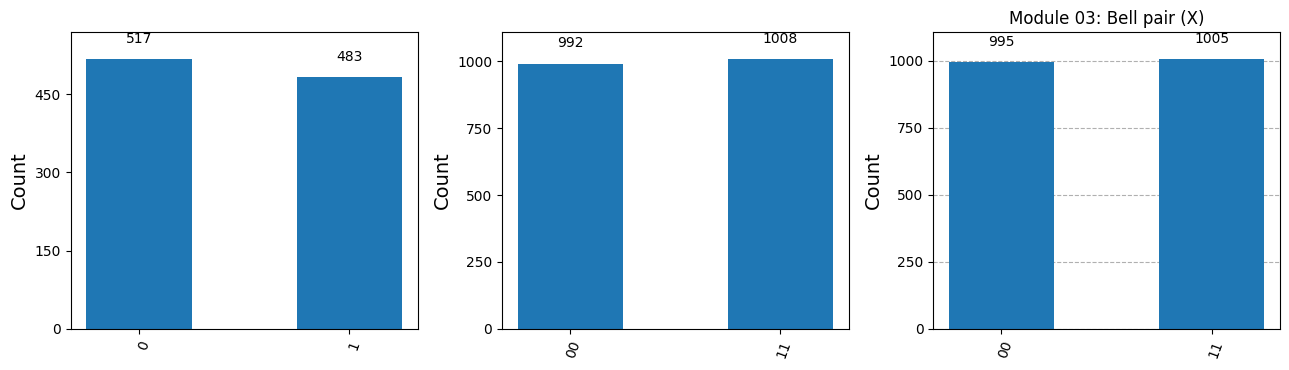

In [15]:
# Final summary: verify deterministic results and visualize key distributions
print("=== FINAL REPRODUCIBILITY CHECK ===")
print("Module 01 always-1:", counts_one)
print("Module 01 fair superposition:", counts_rand)
print("Module 01 HH:", counts_silver)
print("Module 01 target 101:", counts_gold)
print("Module 03 Bell Z:", counts_bell)
print("Module 03 Bell X:", counts_quantum_x)
print("Module 03 CHSH S:", round(S, 4), "+/-", round(S_se, 4))
print("Module 05 decoded message:", repr(decoded_message))
print("Module 06 teleportation receiver verification:", q2_results)
print("Module 06 without classical feed-forward:", q2_no_corr)

# Deterministic and decoding checks.
assert counts_one == {"1": 1000}, "Module 01 X circuit should always measure 1."
assert counts_silver == {"0": 1000}, "Module 01 H-H circuit should return 0."
assert counts_gold == {"101": 1000}, "Module 01 target circuit should return 101."
assert len(triples) == 32 and decoded_message == "ECHO", "Module 05 decoding check failed."
assert S - 2*S_se > 2, "CHSH estimate is not more than 2 by two standard errors; rerun and inspect."
assert q2_results["0"] == 2000, "Teleportation verification for |+> did not pass in every shot."
print("\\nAll deterministic, CHSH-statistical, decoding, and teleportation checks passed.")

# Histograms
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
plot_histogram([counts_rand], ax=axes[0], title="Module 01: H gate")
plot_histogram([counts_bell], ax=axes[1], title="Module 03: Bell pair (Z)")
plot_histogram([counts_quantum_x], ax=axes[2], title="Module 03: Bell pair (X)")
plt.tight_layout()
plt.show()
